In [ ]:
import pandas as pd
import matplotlib as plt
import numpy as np
import geopandas as gpd
import seaborn as sns
import matplotlib.pyplot as plt
import glob
import matplotlib.pyplot as plt

import re




In [ ]:
# crash_18 = pd.read_csv('crash_data_2018.csv')

# # crash_18.head()

crash_19 = pd.read_csv('crash_data_2019.csv')
crash_19 = crash_19.drop_duplicates()
print(crash_19['Intersecting Road'].unique())

In [10]:
# import glob
# import re
# import pandas as pd
# import geopandas as gpd

# 1. LOAD & MERGE ALL 2018–2024 FILES
files = sorted(glob.glob("*crash*.csv"))  # Matches crash_data_*.csv, crash_Data_2021.csv, crashes_*.csv
dfs = [pd.read_csv(f, low_memory=False) for f in files]

# Verify identical schemas across all years before concatenating
assert all(list(df.columns) == list(dfs[0].columns) for df in dfs), "Column mismatch!"
df = pd.concat(dfs, ignore_index=True).drop_duplicates(subset=["Crash ID"])

# 2. CREATE DATETIME COLUMN FROM YEAR, MONTH, DAY, HOUR
# Note: Year (2018-2024), Month (1-12), Day (1-31), and Hour (0-23) are clean integers across all 7 files
df["crash_datetime"] = pd.to_datetime(
    df[["Year", "Month", "Day", "Hour"]],
    errors="coerce"
)

# 3. STANDARDIZE PRIMARY & INTERSECTING ROAD NAMES
EXACT_FIXES = {
    "8MILE": "8 MILE",
    "GRANDRIVER": "GRAND RIVER",
    "WESTEND": "WEST END",
    "FEILDING": "FIELDING",
    "VASSSAR": "VASSAR",
    "WAVENY": "WAVENEY",
    "SAINT ANTOINE": "ST ANTOINE",
}

TOKEN_REPLACEMENTS = {
    r"\b2ND\b": "SECOND",
    r"\b3RD\b": "THIRD",
    r"\bJOHN C LODGE\b": "LODGE",
    r"\bEDSEL FORD\b": "I 94",
    r"^96 SERVICE": "I 96 SERVICE",
}

def clean_road_names(series: pd.Series) -> pd.Series:
    s = (
        series.fillna("")
        .astype(str)
        .str.upper()
        .str.strip()
        # Remove periods and collapse multiple spaces
        .str.replace(r"\.", "", regex=True)
        .str.replace(r"\s+", " ", regex=True)
        # Standardize service drive endings ("S D", "SD", or trailing "SERVICE" -> "SERVICE DRIVE")
        .str.replace(r"\b(S\s*D|SERVICE)$", "SERVICE DRIVE", regex=True)
        # Strip trailing street-type suffixes so "WOODWARD" and "WOODWARD AVE" match
        .str.replace(r"\b(ST|AVE|RD|BLVD|DR)$", "", regex=True)
        .str.strip()
    )

    for pattern, repl in TOKEN_REPLACEMENTS.items():
        s = s.str.replace(pattern, repl, regex=True)

    return s.replace(EXACT_FIXES).str.strip()

df["primary_road_clean"] = clean_road_names(df["Primary Road"])
df["intersecting_road_clean"] = clean_road_names(df["Intersecting Road"])

# Optional: Create an order-independent intersection key (so "A & B" matches "B & A")
df["intersection_key"] = df.apply(
    lambda r: " & ".join(sorted([r["primary_road_clean"], r["intersecting_road_clean"]])),
    axis=1,
)

# 4. CONVERT TO GEOPANDAS GEODATAFRAME (WGS84 / EPSG:4326)
merged_crash_gdf = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(df["Longitude"], df["Latitude"]),
    crs="EPSG:4326",
)

print(f"Merged GeoDataFrame shape: {merged_crash_gdf.shape}")
print(f"Date range: {merged_crash_gdf['crash_datetime'].min()} to {merged_crash_gdf['crash_datetime'].max()}")
print(f"Unique intersections: {merged_crash_gdf['intersection_key'].nunique()}")

Merged GeoDataFrame shape: (967, 61)
Date range: 2018-01-16 19:00:00 to 2024-12-31 18:00:00
Unique intersections: 813


In [18]:
print(merged_crash_gdf['Most Severe Injury'])

0      5
1      5
2      1
3      3
4      3
      ..
962    2
963    2
964    5
965    3
966    3
Name: Most Severe Injury, Length: 967, dtype: int64


In [13]:
#ensuring the GeoDataFrame is in Web Mercator projection for mapping
merge_crash_gdf = merged_crash_gdf.to_crs(epsg=3857)


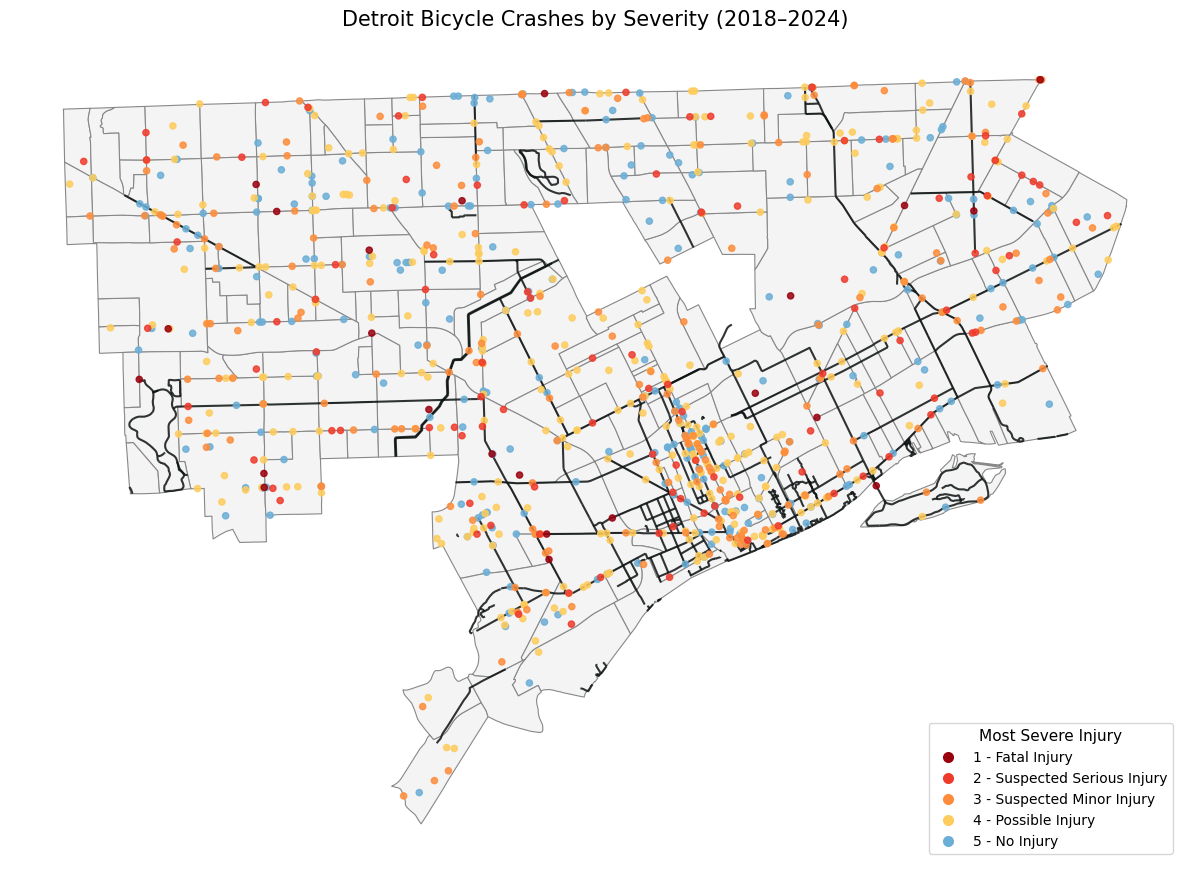

In [58]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# 1. Map codes 1–5 to your exact legend labels
severity_labels = {
    1: "1 - Fatal Injury",
    2: "2 - Suspected Serious Injury",
    3: "3 - Suspected Minor Injury",
    4: "4 - Possible Injury",
    5: "5 - No Injury",
}

# Assign intuitive colors from most severe (dark red) to least severe (blue)
severity_colors = {
    "1 - Fatal Injury": "#99000d",
    "2 - Suspected Serious Injury": "#ef3b2c",
    "3 - Suspected Minor Injury": "#fd8d3c",
    "4 - Possible Injury": "#fecc5c",
    "5 - No Injury": "#6baed6",
}

merged_crash_gdf["severity_label"] = merged_crash_gdf["Most Severe Injury"].map(severity_labels)
merged_crash_gdf["point_color"] = merged_crash_gdf["severity_label"].map(severity_colors)

# Sort descending (5 -> 1) so Fatal and Serious crashes draw ON TOP of minor crashes
plot_gdf = merged_crash_gdf.sort_values("Most Severe Injury", ascending=False)

# 2. Plot Detroit GeoJSON base map + crash points
fig, ax = plt.subplots(figsize=(12, 12))

detroit_gdf = gpd.read_file("Current_City_of_Detroit_Neighborhoods_-37248265170297756.geojson")
detroit_gdf = detroit_gdf.to_crs(merged_crash_gdf.crs)
detroit_gdf.plot(
    ax=ax,
    color="#f4f4f4",       # Light gray fill
    edgecolor="#888888",   # Subtle boundary/neighborhood lines
    linewidth=0.8,
    zorder=1               # Keep base layer underneath
)
bike_lanes_gdf.plot(
    ax=ax,
    color="#0C1111",
    linewidth=1.5,
    alpha=0.85,
    zorder=2
)
plot_gdf.plot(
    ax=ax,
    color=plot_gdf["point_color"],
    markersize=20,
    alpha=0.85,
    zorder=2,
)

# 3. Build the custom legend in exact 1–5 order
legend_handles = [
    Line2D(
        [0], [0],
        marker="o",
        color="w",                      # Hide connecting line
        label=label,
        markerfacecolor=color,
        markersize=9,                   # Keeps legend dots large and readable
    )
    for label, color in severity_colors.items()
]

ax.legend(
    handles=legend_handles,
    title="Most Severe Injury",
    title_fontsize=11,
    fontsize=10,
    loc="lower right",                  # Adjust to "upper left", "lower left", etc. if needed
    frameon=True,
    facecolor="white",
    edgecolor="#cccccc",
)

ax.set_title("Detroit Bicycle Crashes by Severity (2018–2024)", fontsize=15, pad=12)
ax.set_axis_off()
plt.tight_layout()
plt.show()

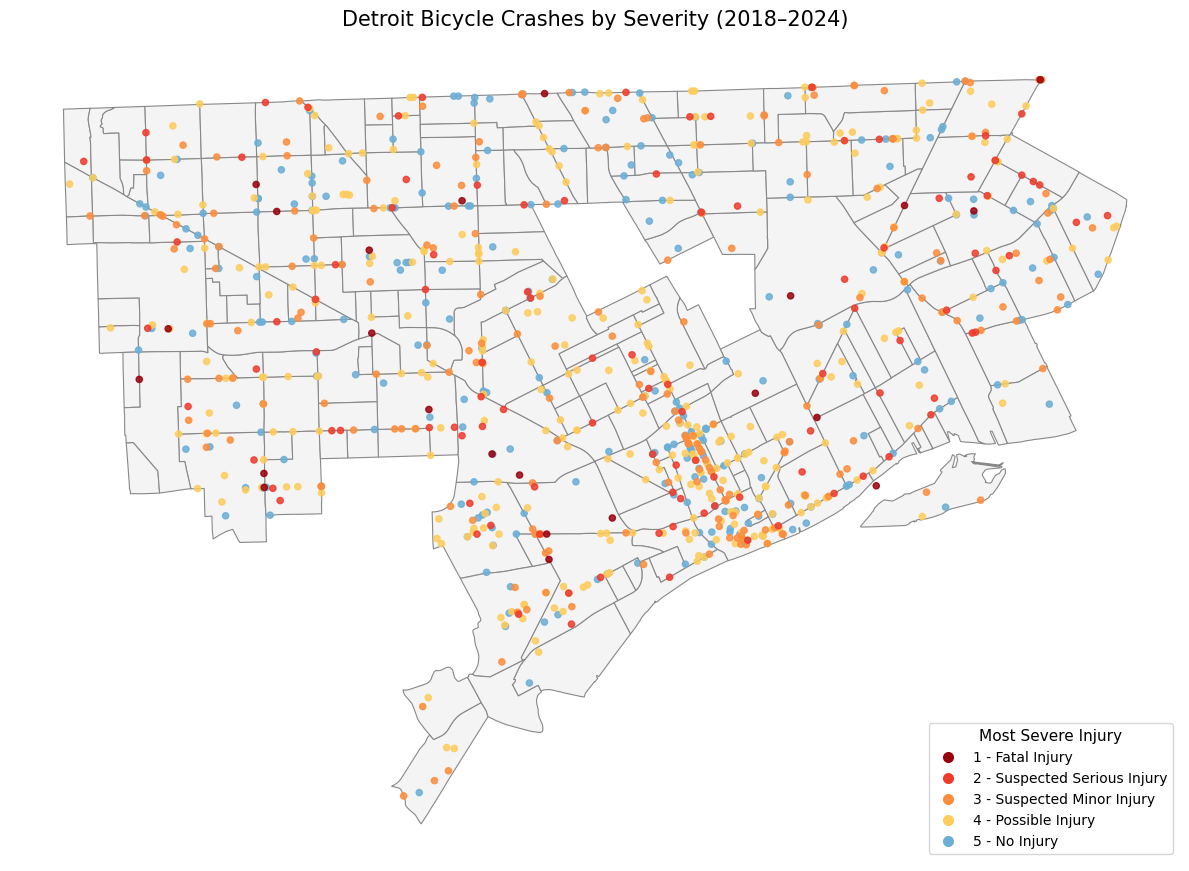

In [20]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# 1. Map codes 1–5 to your exact legend labels
severity_labels = {
    1: "1 - Fatal Injury",
    2: "2 - Suspected Serious Injury",
    3: "3 - Suspected Minor Injury",
    4: "4 - Possible Injury",
    5: "5 - No Injury",
}

# Assign intuitive colors from most severe (dark red) to least severe (blue)
severity_colors = {
    "1 - Fatal Injury": "#99000d",
    "2 - Suspected Serious Injury": "#ef3b2c",
    "3 - Suspected Minor Injury": "#fd8d3c",
    "4 - Possible Injury": "#fecc5c",
    "5 - No Injury": "#6baed6",
}

merged_crash_gdf["severity_label"] = merged_crash_gdf["Most Severe Injury"].map(severity_labels)
merged_crash_gdf["point_color"] = merged_crash_gdf["severity_label"].map(severity_colors)

# Sort descending (5 -> 1) so Fatal and Serious crashes draw ON TOP of minor crashes
plot_gdf = merged_crash_gdf.sort_values("Most Severe Injury", ascending=False)

# 2. Plot Detroit GeoJSON base map + crash points
fig, ax = plt.subplots(figsize=(12, 12))

detroit_gdf = gpd.read_file("Current_City_of_Detroit_Neighborhoods_-37248265170297756.geojson")
detroit_gdf = detroit_gdf.to_crs(merged_crash_gdf.crs)
detroit_gdf.plot(
    ax=ax,
    color="#f4f4f4",       # Light gray fill
    edgecolor="#888888",   # Subtle boundary/neighborhood lines
    linewidth=0.8,
    zorder=1               # Keep base layer underneath
)

plot_gdf.plot(
    ax=ax,
    color=plot_gdf["point_color"],
    markersize=20,
    alpha=0.85,
    zorder=2,
)

# 3. Build the custom legend in exact 1–5 order
legend_handles = [
    Line2D(
        [0], [0],
        marker="o",
        color="w",                      # Hide connecting line
        label=label,
        markerfacecolor=color,
        markersize=9,                   # Keeps legend dots large and readable
    )
    for label, color in severity_colors.items()
]

ax.legend(
    handles=legend_handles,
    title="Most Severe Injury",
    title_fontsize=11,
    fontsize=10,
    loc="lower right",                  # Adjust to "upper left", "lower left", etc. if needed
    frameon=True,
    facecolor="white",
    edgecolor="#cccccc",
)

ax.set_title("Detroit Bicycle Crashes by Severity (2018–2024)", fontsize=15, pad=12)
ax.set_axis_off()
plt.tight_layout()
plt.show()

In [32]:
merged_crash_gdf.columns

Index(['ObjectId', 'Crash ID', 'Primary Road', 'Intersecting Road',
       'Crash Date', 'Day', 'Month', 'Year', 'Hour', 'Weekday',
       'Crash Type Code', 'Highway Classification Code', 'Community Code',
       'Jurisdiction Code', 'Lane Departure Type Code', 'Surface Type',
       'Road Condition', 'Weather Condition', 'Lighting Condition',
       'Speed Limit', 'Lanes', 'Units', 'Occupants', 'Most Severe Injury',
       'Fatal Injuries', 'Suspected Serious Injuries',
       'Suspected Minor Injuries', 'Possible Injuries', 'Property Damage Only',
       'Secondary Crash', 'Traffic Control', 'Red Light Run', 'Hit and Run',
       'Alcohol', 'Drugs', 'Unbelted Person', 'Work Zone', 'Speeding Driver',
       'Distracted Driver', 'Driveway', 'Pedestrian', 'Elderly Driver',
       'Young Driver', 'Commercial Vehicle', 'Emergency Vehicles', 'Train',
       'School Bus', 'Motorcycle', 'Bicycle', 'Deer', 'Longitude', 'Latitude',
       'geom', 'geog', 'x', 'y', 'crash_datetime', 'primary_r

In [57]:
traffic_signals_gdf = gpd.read_file("Traffic_Sign_Locations.geojson")
bike_lanes_gdf = gpd.read_file("Cycling_Infrastructure_(Bike_Lanes).geojson")
bike_lanes_gdf.head()

,OBJECTID_1,Type,Networks,geometry
0,4,None,N/A,"LINESTRING Z (-82.9389 42.37514 0, -82.93881 4..."
1,5,None,N/A,"LINESTRING Z (-82.93953 42.37488 0, -82.93917 ..."
2,6,None,N/A,"LINESTRING Z (-83.12679 42.40248 0, -83.12698 ..."
3,7,None,N/A,"LINESTRING Z (-83.12258 42.39385 0, -83.1231 4..."
4,8,None,N/A,"LINESTRING Z (-82.98112 42.38311 0, -82.98363 ..."


In [25]:
traffic_signals_gdf.dtypes

fid_           int32
refname       object
doctype       object
docname       object
lvldesc       object
level_         int32
ObjectId       int32
geometry    geometry
dtype: object

In [48]:
detroit_gdf = gpd.read_file("Current_City_of_Detroit_Neighborhoods_-37248265170297756.geojson")

Total Bike Crashes Analyzed: 967

           location_category  crash_count  fatal_crashes  serious_crashes  median_dist_m  pct_of_total
        Off Bike Lane (>15m)          703             17               82          654.6          72.7
On / Within 15m of Bike Lane          264              6               23            1.9          27.3


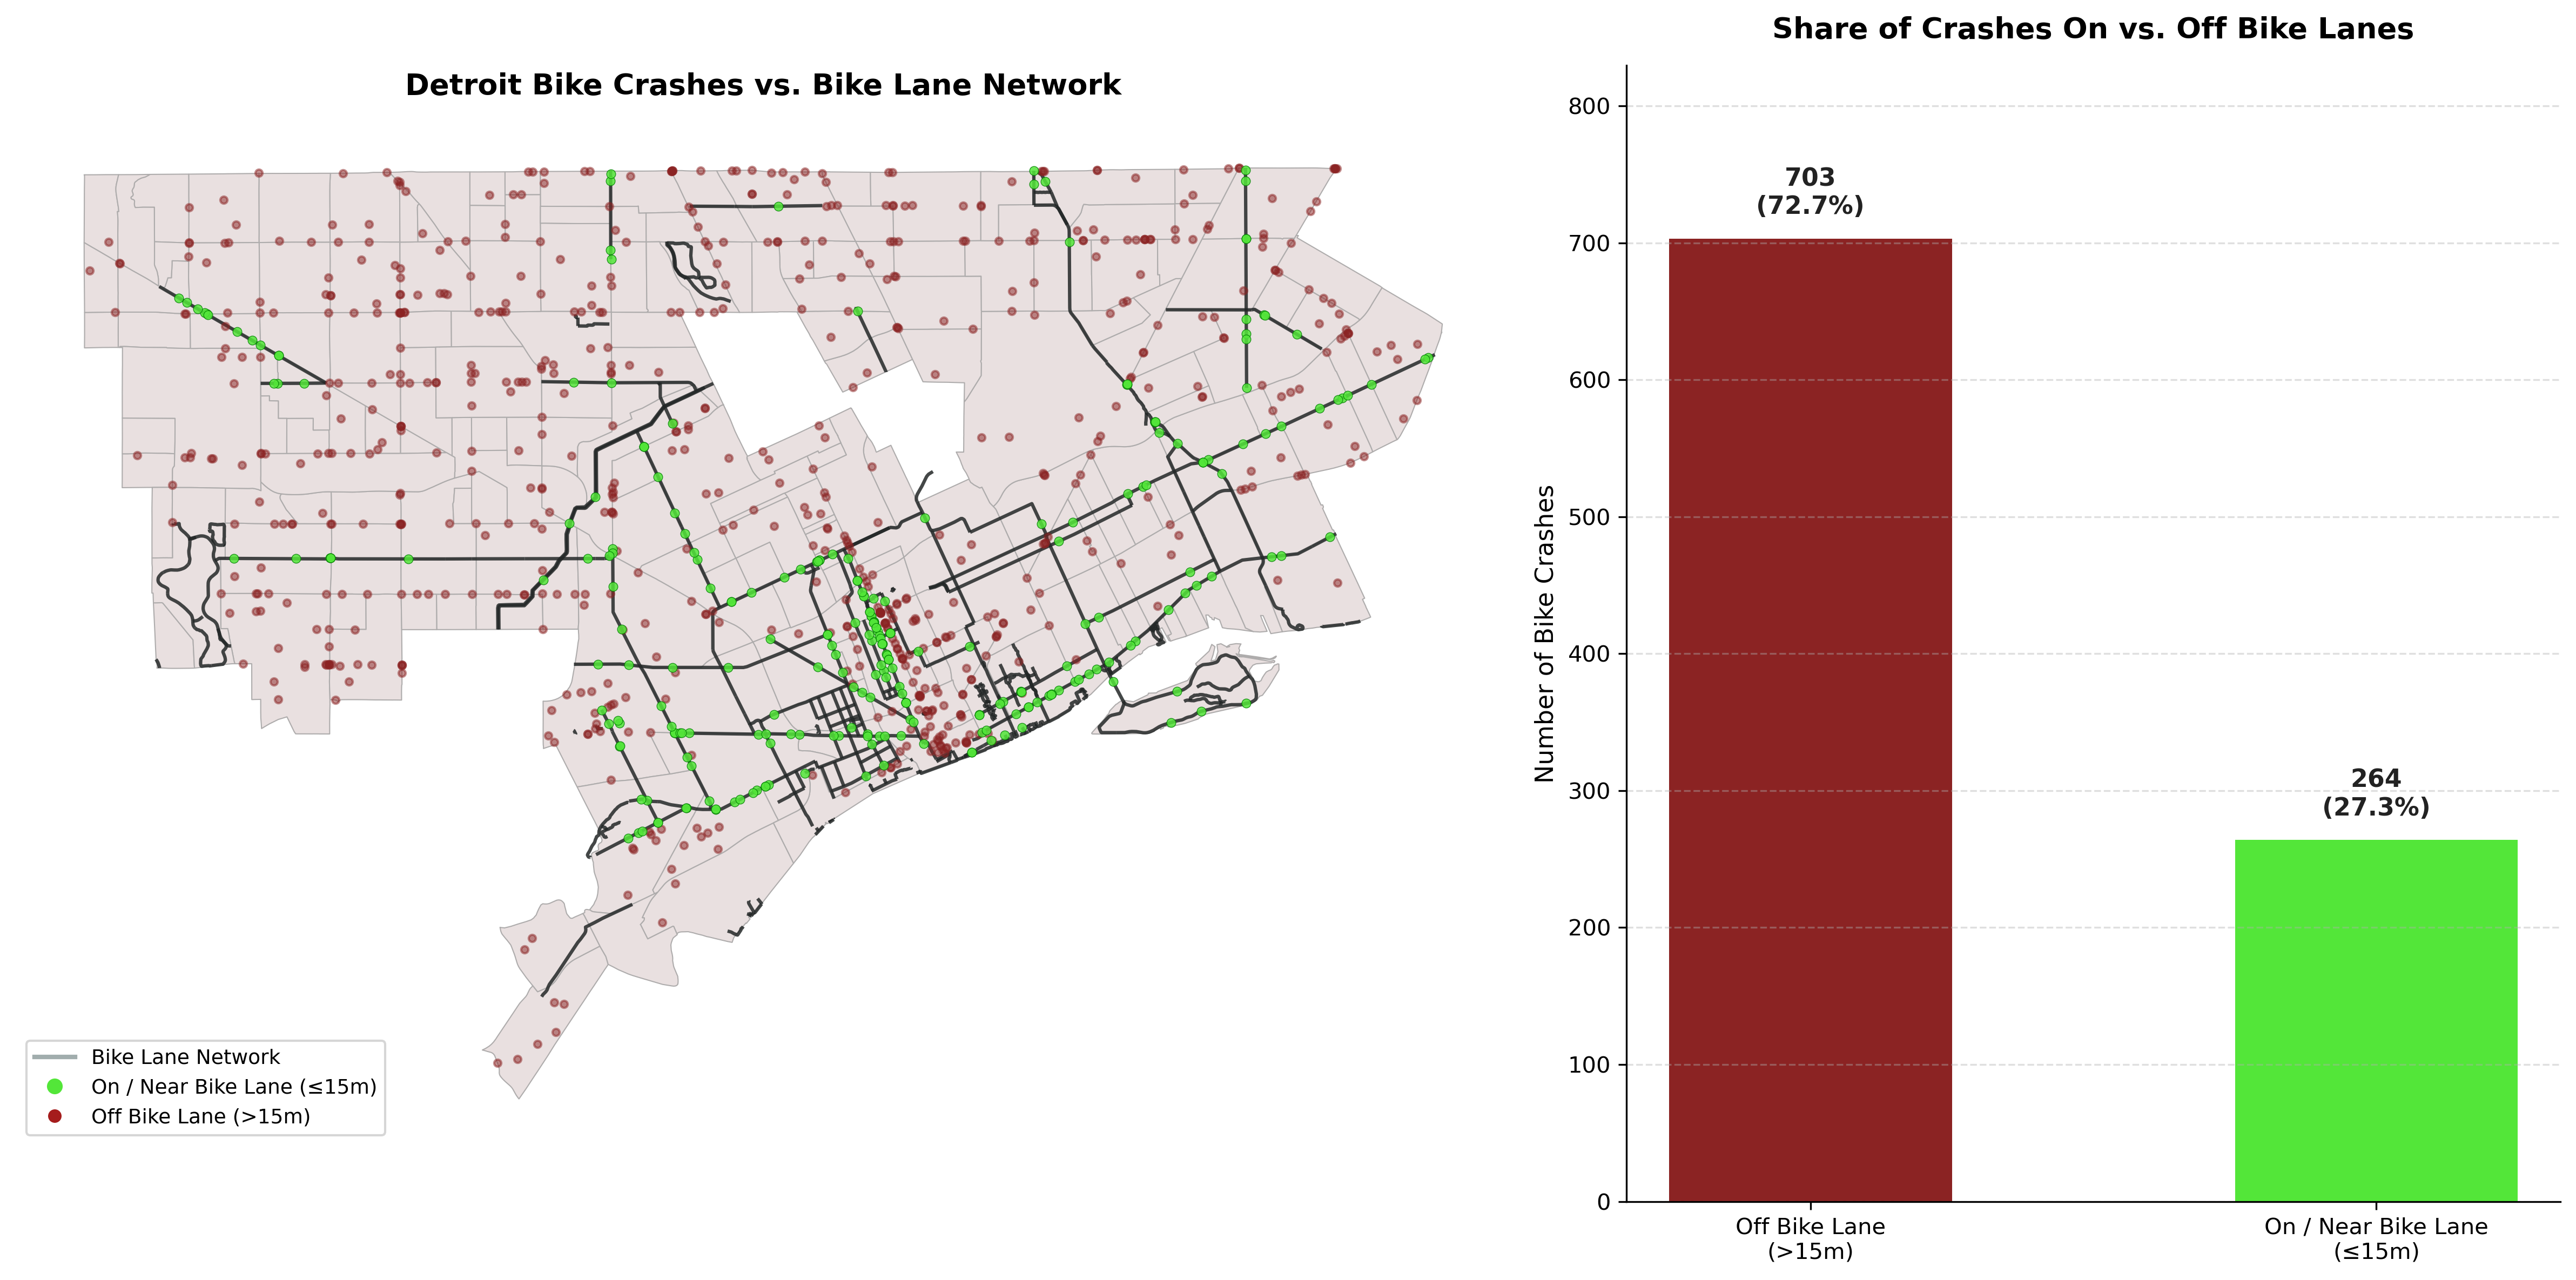

In [ ]:

from matplotlib.lines import Line2D

crashes = merged_crash_gdf   
bike_lanes = bike_lanes_gdf 
neighborhoods = detroit_gdf           

if not isinstance(crashes, gpd.GeoDataFrame):
    crashes_clean = crashes.dropna(subset=["Longitude", "Latitude"]).copy()
    crashes_gdf = gpd.GeoDataFrame(
        crashes_clean,
        geometry=gpd.points_from_xy(crashes_clean["Longitude"], crashes_clean["Latitude"]),
        crs="EPSG:4326"
    )
else:
    crashes_gdf = crashes[crashes.geometry.notna() & ~crashes.geometry.is_empty].copy()
    if crashes_gdf.crs is None:
        crashes_gdf = crashes_gdf.set_crs("EPSG:4326")

bike_lanes_gdf = bike_lanes.copy()
if bike_lanes_gdf.crs is None:
    bike_lanes_gdf = bike_lanes_gdf.set_crs("EPSG:4326")

METRIC_CRS = "EPSG:32617"  # Accurate metric CRS for Detroit, MI
crashes_proj = crashes_gdf.to_crs(METRIC_CRS)
lanes_proj = bike_lanes_gdf.to_crs(METRIC_CRS)

# Find nearest bike lane to every crash and compute distance in meters
crashes_near_lanes = gpd.sjoin_nearest(
    crashes_proj,
    lanes_proj[["geometry"]],
    how="left",
    distance_col="dist_to_bike_lane_m"
)

crashes_near_lanes = crashes_near_lanes[~crashes_near_lanes.index.duplicated(keep="first")].copy()

BUFFER_METERS = 15
crashes_near_lanes["on_bike_lane"] = crashes_near_lanes["dist_to_bike_lane_m"] <= BUFFER_METERS
crashes_near_lanes["location_category"] = crashes_near_lanes["on_bike_lane"].map(
    {True: f"On / Within {BUFFER_METERS}m of Bike Lane", False: f"Off Bike Lane (>{BUFFER_METERS}m)"}
)

total_crashes = len(crashes_near_lanes)
summary = (
    crashes_near_lanes.groupby("location_category")
    .agg(
        crash_count=("Crash ID", "count"),
        fatal_crashes=("Fatal Injuries", lambda s: (s > 0).sum()),
        serious_crashes=("Suspected Serious Injuries", lambda s: (s > 0).sum()),
        median_dist_m=("dist_to_bike_lane_m", "median")
    )
    .reset_index()
)
summary["pct_of_total"] = (summary["crash_count"] / total_crashes * 100).round(1)
summary["median_dist_m"] = summary["median_dist_m"].round(1)

print(f"Total Bike Crashes Analyzed: {total_crashes:,}\n")
print(summary.to_string(index=False))

fig, (ax_map, ax_bar) = plt.subplots(
    1, 2,
    figsize=(16, 8),
    gridspec_kw={"width_ratios": [1.6, 1]},
    dpi=300
)

if neighborhoods is not None:
    nhoods_proj = neighborhoods.to_crs(METRIC_CRS) if neighborhoods.crs else neighborhoods.set_crs("EPSG:4326").to_crs(METRIC_CRS)
    nhoods_proj.plot(ax=ax_map, color="#e9e0e0", edgecolor="#aeacac", linewidth=0.5, zorder=1)

lanes_proj.plot(
    ax=ax_map,
    color="#232727",
    linewidth=1.5,
    alpha=0.85,
    zorder=2
)

# Plot off-lane crashes underneath on-lane crashes
off_lane = crashes_near_lanes[~crashes_near_lanes["on_bike_lane"]]
on_lane = crashes_near_lanes[crashes_near_lanes["on_bike_lane"]]

off_lane.plot(
    ax=ax_map,
    color="#8b2323",
    markersize=10,
    alpha=0.5,
    zorder=3
)

on_lane.plot(
    ax=ax_map,
    color="#53e639",
    markersize=16,
    alpha=0.85,
    edgecolor="green",
    linewidth=0.3,
    zorder=4
)

# Legend & Map Formatting
map_legend = [
    Line2D([0], [0], color="#A1ADAD", lw=2, label="Bike Lane Network"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="#53e639", markersize=8,
           label=f"On / Near Bike Lane (≤{BUFFER_METERS}m)"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="#a51c1c", markersize=7,
           label=f"Off Bike Lane (>{BUFFER_METERS}m)")
]
ax_map.legend(handles=map_legend, loc="lower left", frameon=True, facecolor="white", fontsize=9)
ax_map.set_title("Detroit Bike Crashes vs. Bike Lane Network", fontsize=13, fontweight="bold", pad=12)
ax_map.set_axis_off()

# Bar Chart Comparison
categories = [f"Off Bike Lane\n(>{BUFFER_METERS}m)", f"On / Near Bike Lane\n(≤{BUFFER_METERS}m)"]
counts = [len(off_lane), len(on_lane)]
pcts = [c / total_crashes * 100 for c in counts]
colors = ["#8b2323", "#53e639"]

bars = ax_bar.bar(categories, counts, color=colors, width=0.5)

for bar, count, pct in zip(bars, counts, pcts):
    ax_bar.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + (max(counts) * 0.02),
        f"{count:,}\n({pct:.1f}%)",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
        color="#222222"
    )

ax_bar.set_ylim(0, max(counts) * 1.18)
ax_bar.set_ylabel("Number of Bike Crashes", fontsize=11)
ax_bar.set_title("Share of Crashes On vs. Off Bike Lanes", fontsize=13, fontweight="bold", pad=12)
ax_bar.spines["top"].set_visible(False)
ax_bar.spines["right"].set_visible(False)
ax_bar.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig("bike_crashes_vs_bike_lanes.png", dpi=300, bbox_inches="tight")
plt.show()